# Grupa A – jakość danych

Waszym celem jest odpowiedzieć na pytanie:

> **Czy te dane są wystarczająco poprawne i spójne, aby rozpocząć modelowanie?**

Przeczytaj również `readme/README_GRUPA_A.md`.

!git clone https://github.com/poochacz/Podstawy_technologii_ML.git /content/eda_bank_marketing_colab

In [1]:
# Działa w Google Colabie oraz lokalnie w VS Code.
import sys
from pathlib import Path

COLAB_ROOT = Path("/content/eda_bank_marketing_colab/01_eda_bank_marketing_colab")
current = Path.cwd().resolve()
candidates = [COLAB_ROOT]
for directory in (current, *current.parents):
    candidates.extend((directory / "01_eda_bank_marketing_colab", directory))

ROOT = next(
    (candidate.resolve() for candidate in candidates if (candidate / "scripts").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Nie znaleziono katalogu projektu. Otwórz workspace zawierający "
        "01_eda_bank_marketing_colab albo uruchom notebook w Colabie."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = ROOT / "data"
print("Środowisko gotowe:", ROOT)

Środowisko gotowe: C:\Users\dariu\Documents\Studia Kato\Koźmiński\podstawy ML\podstawy_ML_repo\Podstawy_technologii_ML\01_eda_bank_marketing_colab


In [2]:
from scripts.data_setup import prepare_workshop_data

df, reference = prepare_workshop_data(
    data_dir=DATA_DIR,
    n=2000,
    random_state=42
)

## 1. Braki danych: NaN czy „unknown”?

In [3]:
from scripts.group_a import missing_values_analysis

missing_values_analysis(df)

Liczba wierszy z co najmniej jednym NaN: 85
Liczba wierszy z co najmniej jednym 'unknown': 163
Liczba wierszy z NaN lub 'unknown' (bez podwójnego liczenia): 246


,zmienna,NaN (wiersze),'unknown' (wiersze),łącznie w zmiennej
0,age,18,0,18
1,job,0,17,17
2,education,24,84,108
3,housing,14,52,66
4,contact,0,0,0
5,month,8,8,16
6,duration,8,4,12
7,campaign,8,4,12
8,pdays,8,4,12
9,y,0,0,0


**Pytanie do decyzji:** Czy możemy usunąć wszystkie wiersze, w których występuje `NaN` lub `"unknown"`?

`NaN` oznacza brak zapisanej wartości, a `"unknown"` jest jawnym tekstem w danych. Usunięcie obu rodzajów może ograniczyć liczbę obserwacji albo pozbawić nas informacji.

In [4]:
from scripts.group_a import missing_values_for_column

# Zmień nazwę zmiennej, aby przeanalizować inną kolumnę.
ZMIENNA = "duration"
missing_values_for_column(df, ZMIENNA)

Braki informacji w zmiennej 'duration' (na 2000 wierszy):


,typ wartości,liczba wierszy,udział wierszy (%)
0,NaN,8,0.4
1,'unknown',4,0.2


Przykładowe wiersze z brakami w wybranej zmiennej:


,wiersz,typ braku,age,job,education,housing,contact,month,duration,campaign,pdays,y
215,215,Unknown,42.0,admin.,university.degree,no,telephone,jun,unknown,2.0,999.0,no
1508,1508,NaN,34.0,blue-collar,basic.6y,no,cellular,may,NaN,3.0,999.0,no
1213,1213,NaN,59.0,retired,basic.4y,no,cellular,jul,NaN,2.0,999.0,no
202,202,NaN,39.0,blue-collar,basic.6y,yes,telephone,may,NaN,1.0,999.0,no
1983,1983,Unknown,43.0,blue-collar,basic.4y,yes,telephone,may,unknown,2.0,999.0,no
69,69,NaN,29.0,admin.,university.degree,yes,cellular,jul,NaN,2.0,999.0,no
1964,1964,Unknown,62.0,technician,professional.course,yes,cellular,may,unknown,2.0,999.0,no
845,845,NaN,31.0,blue-collar,high.school,yes,cellular,may,NaN,2.0,999.0,no
1743,1743,NaN,29.0,admin.,high.school,yes,cellular,may,NaN,2.0,999.0,yes
470,470,Unknown,29.0,blue-collar,basic.4y,no,telephone,may,unknown,1.0,999.0,no


## 2. Wartości nierzeczywiste i anomalie

In [3]:
from scripts.group_a import (
    anomaly_candidates,
    display_anomaly_candidates,
    sample_anomaly_candidates,
)

kandydaci = anomaly_candidates(df)
kandydaci_przykladowi = sample_anomaly_candidates(kandydaci, sample_size=10)
display_anomaly_candidates(kandydaci_przykladowi, include_row=False)

zmienna,wartość
age,18.0
age,77.0
age,86.0
age,21.0
campaign,17.0
campaign,28.0
campaign,15.0
duration,1297.0
duration,1975.0
duration,1298.0


In [4]:
from scripts.group_a import display_anomaly_rows

display_anomaly_rows(df, kandydaci_przykladowi)

Pełne dane dla wybranych przykładów (maksymalnie 10 wierszy):


,wiersz,zmienna_odstająca,wartość_odstająca,age,job,education,housing,contact,month,duration,campaign,pdays,y
0,139,age,18.0,18.0,student,unknown,yes,cellular,may,183.0,1.0,7.0,no
1,498,age,77.0,77.0,retired,unknown,yes,cellular,may,318.0,3.0,999.0,no
2,1167,age,86.0,86.0,retired,professional.course,no,telephone,dec,343.0,2.0,999.0,yes
3,1824,age,21.0,21.0,student,high.school,no,cellular,may,24.0,1.0,999.0,no
4,721,campaign,17.0,44.0,admin.,university.degree,no,telephone,may,10.0,17.0,999.0,no
5,954,campaign,28.0,43.0,unemployed,basic.9y,no,telephone,jun,633.0,28.0,999.0,no
6,1630,campaign,15.0,56.0,unknown,unknown,yes,telephone,may,174.0,15.0,999.0,no
7,384,duration,1297.0,43.0,blue-collar,basic.9y,no,cellular,may,1297.0,2.0,999.0,no
8,507,duration,1975.0,NaN,blue-collar,basic.9y,yes,cellular,may,1975.0,5.0,999.0,yes
9,1194,duration,1298.0,29.0,admin.,basic.9y,no,telephone,jun,1298.0,2.0,999.0,no


In [5]:
from scripts.group_a import display_anomaly_candidates

# Wybierz zmienną: "age", "duration", "campaign" albo "pdays".
ZMIENNA_ANOMALII = "age"
kandydaci_zmiennej = kandydaci.loc[
    kandydaci["zmienna"].eq(ZMIENNA_ANOMALII)
].reset_index(drop=True)

display_anomaly_candidates(kandydaci_zmiennej)

wiersz,zmienna,wartość,sygnał,dlaczego
139,age,18.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.
250,age,22.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.
273,age,20.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.
319,age,160.0,wartość niemożliwa,Wiek powinien mieścić się w zakresie 0–110 lat.
324,age,22.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.
346,age,19.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.
464,age,65.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.
469,age,18.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.
471,age,20.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.
488,age,69.0,rzadka skrajna wartość,Wartość leży poza zakresem około 98% poprawnych obserwacji (23.0–63.2); może być prawidłowa.


### Wasza ocena

Przejrzyjcie przykładowe wiersze i samodzielnie zdecydujcie, które wartości są błędne, a które mogą być rzadkie, lecz prawidłowe. Widok wybranej zmiennej powyżej pokazuje wszystkie znalezione przypadki i numery wierszy.

W komórce poniżej wpiszcie decyzje jako `(numer_wiersza, "zmienna"): "zostaw"` albo `"usuń"`. Użyjcie osobnego identyfikatora dla każdej osoby lub grupy; wynik zapisze się do osobnego pliku CSV.

In [ ]:
from scripts.group_a import save_anomaly_decisions

# Zmień identyfikator, aby każdy uczestnik zapisał osobny plik.
OCENIAJACY = "grupa_01"
DECYZJE = {
    # (numer_wiersza, "zmienna"): "zostaw",
    # (numer_wiersza, "zmienna"): "usuń",
}

save_anomaly_decisions(
    candidates=kandydaci,
    decisions=DECYZJE,
    reviewer=OCENIAJACY,
    output_path=DATA_DIR / f"decyzje_anomalie_{OCENIAJACY}.csv",
)

## 3. Szczególny przypadek: `pdays`

,liczba
pdays,
999.0,1924
6.0,21
3.0,11
NaN,8
4.0,6
2.0,5
unknown,4
12.0,4
9.0,3


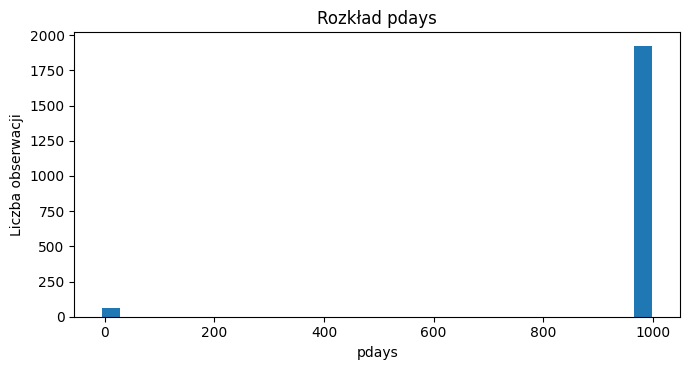

In [6]:
from scripts.group_a import show_pdays_distribution

show_pdays_distribution(df)

`pdays=999` wygląda jak bardzo duża wartość odstająca.

**Sprawdźcie w opisie danych UCI, co oznacza.**

## 4. Czy kategoria wiąże się z założeniem lokaty?

`y = "yes"` oznacza, że klient założył lokatę terminową. `housing` mówi, czy klient ma kredyt mieszkaniowy, a `contact` wskazuje kanał kontaktu.

Porównajcie odsetek założonych lokat w każdej kategorii oraz liczebność grup. To opisowa zależność, nie dowód, że kredyt mieszkaniowy lub kanał kontaktu spowodował wynik.

In [3]:
from scripts.group_a import categorical_target_report

raport_kategorii = categorical_target_report(
    df,
    columns=("housing", "contact"),
)

Porównanie odsetka klientów, którzy założyli lokatę (y='yes'), w obrębie każdej kategorii:


,zmienna,wartość kategorii,liczba klientów,liczba założonych lokat,odsetek klientów z lokatą (%)
0,contact,cellular,1304,188,14.4
1,contact,telephone,696,33,4.7
2,housing,brak danych,14,2,14.3
3,housing,no,898,101,11.2
4,housing,yes,1036,116,11.2
5,housing,unknown,52,2,3.8


## 5. Czy brak wieku wiąże się z wynikiem kampanii?

W tym zbiorze `y = "yes"` oznacza założenie lokaty terminowej, nie przyznanie kredytu. Sprawdzimy korelację wieku z tym wynikiem oraz porównamy odsetek założonych lokat wśród osób z brakującym wiekiem i osób w wieku 35–45 lat.

Wiek poza zakresem 0–110 nie bierze udziału w obliczaniu korelacji. Wyniki pokazują zależność w tej próbce, nie przyczynowość.

In [3]:
from scripts.group_a import age_target_analysis, compare_age_imputation

compare_age_imputation(df)
age_target_analysis(df)

,wariant,n,średnia,mediana,odchylenie_std
0,oryginał_bez_braków,1980,39.62,38.0,10.02
1,średnia,2000,39.62,38.0,9.97
2,mediana,2000,39.60,38.0,9.97


Wynik y='yes' oznacza założenie lokaty terminowej.
Korelacja wieku z założeniem lokaty (Pearson r, wiek 0–110, n=1980): 0.068
Wartość r opisuje współwystępowanie, nie dowodzi związku przyczynowego.
Decyzje dotyczące lokaty: brak wieku porównany z osobami w wieku 35–45 lat.


,grupa klientów,liczba klientów,wynik znany (yes/no),założyli lokatę (yes),nie założyli lokaty (no),odsetek lokat (%)
0,Brakujący wiek,18,18,1,17,5.6
1,Wiek 35–45 lat,718,718,57,661,7.9


,grupa klientów,liczba klientów,wynik znany (yes/no),założyli lokatę (yes),nie założyli lokaty (no),odsetek lokat (%)
0,Brakujący wiek,18,18,1,17,5.6
1,Wiek 35–45 lat,718,718,57,661,7.9


## Przygotujcie 2–3 wnioski

1. Co należy poprawić przed treningiem?
2. Co zostawilibyście mimo że wygląda nietypowo?
3. Które decyzje wymagają wiedzy biznesowej?